# Store Level Signal Aggregation and Partial Pooling

After this notebook, we will have a store level dataset of partially pooled store raw mean scores and z scores for each store. 

In [5]:
import pandas as pd
import numpy as np


#load dataset with manual validation predictions
reviews = pd.read_csv(
    "data/manual_validation/reviews_with_manual_validation.csv"
)

In [9]:
# ============================================================
# Filter to reviews assigned to manually valid topics
# ============================================================

valid_reviews = reviews.copy()

# Keep only reviews whose topic was manually reviewed and marked valid.
# This excludes:
# - BERTopic outlier topic (-1), because it has no manual validation
# - topics manually marked invalid
# - topics not yet manually scored
# - topics marked needs_review
valid_reviews = valid_reviews[
    valid_reviews["manual_topic_status"].eq("valid")
].copy()

print("=== Valid review universe ===")
print(f"Original reviews: {len(reviews):,}")
print(f"Reviews from manually valid topics: {len(valid_reviews):,}")
print()
print(f"Valid topics retained: {valid_reviews['topic'].nunique():,}")
print(f"Stores retained: {valid_reviews['placeId'].nunique():,}")


=== Valid review universe ===
Original reviews: 35,779
Reviews from manually valid topics: 8,183

Valid topics retained: 9
Stores retained: 84


## Store-Level Dimension Signal Aggregation

This section converts the review-level topic and dimension predictions into store-level dimension summaries that can be used as inputs for partial pooling. We first filter the review dataset to include only reviews assigned to topics that were manually marked as valid during the validation step. For those reviews, we preserve the original star-based signal definition used in earlier analyses: 1-star reviews are coded as `-1`, 2–4-star reviews as `0`, and 5-star reviews as `+1`. Because reviews can be assigned to more than one access dimension through `pred_dim`, `pred_dim2`, and `pred_dim3`, the data are reshaped into a long review-by-dimension format so that multilabel reviews contribute to each assigned dimension. We then aggregate these signals by store and dimension, computing the raw mean signal, number of reviews, counts of low/neutral/high signals, and a standard error for each store-dimension mean. Finally, these summaries are pivoted into a wide store-level table and merged with store metadata, producing a clean store-level dataset containing raw dimension means, review counts, and uncertainty estimates for each access dimension. This table serves as the direct input to the Bayesian partial pooling step.

In [10]:
# ============================================================
# Store-Level Dimension Signal Aggregation Setup
# ============================================================

import numpy as np
import pandas as pd

DIM_ORDER = [
    "Availability",
    "Accessibility",
    "Accommodation",
    "Affordability",
    "Acceptability",
]

LABEL_COLS = ["pred_dim", "pred_dim2", "pred_dim3"]

Create review level sentiment signal

Signal definition:
1-star reviews      -> -1  ("Low")
2-, 3-, 4-star      ->  0  ("Neutral")
5-star reviews      -> +1  ("High")

In [11]:
# ============================================================
# Create review-level sentiment signal
# ============================================================
# Signal definition:
# 1-star reviews      -> -1  ("Low")
# 2-, 3-, 4-star      ->  0  ("Neutral")
# 5-star reviews      -> +1  ("High")
#
# This signal is computed only after filtering to manually valid topics.

valid_reviews = valid_reviews.copy()

sentiment = np.select(
    [
        valid_reviews["stars"] == 1,
        valid_reviews["stars"].isin([2, 3, 4]),
        valid_reviews["stars"] == 5,
    ],
    [
        "Low",
        "Neutral",
        "High",
    ],
    default="Neutral",
)

valid_reviews["dim_sentiment"] = pd.Categorical(
    sentiment,
    categories=["Low", "Neutral", "High"],
    ordered=True,
)

valid_reviews["dim_signal"] = (
    valid_reviews["stars"]
    .map({1: -1, 2: 0, 3: 0, 4: 0, 5: 1})
    .astype(float)
)

print("=== Review-level signal distribution ===")
print(valid_reviews["dim_sentiment"].value_counts().sort_index())
print()
print(valid_reviews["dim_signal"].value_counts().sort_index())

=== Review-level signal distribution ===
dim_sentiment
Low         329
Neutral    2939
High       4915
Name: count, dtype: int64

dim_signal
-1.0     329
 0.0    2939
 1.0    4915
Name: count, dtype: int64


Melt the dataframe into a long dataframe so that multilabeled reviews count for multiple dimensions. This helps with data scarcity for less well represented dimensions as well. 

In [12]:
# ============================================================
# Expand multilabel predictions to review × dimension rows
# ============================================================
# Each review can contribute to one or more dimensions based on:
# pred_dim, pred_dim2, pred_dim3.
#
# This creates a long dataframe where each row is one review-dimension assignment.

id_cols = [
    "reviewId",
    "placeId",
    "storeNumber",
    "name",
    "stars",
    "dim_signal",
    "dim_sentiment",
    "title",
    "city",
    "state",
    "location/lat",
    "location/lng",
]

# Keep only ID columns that are actually present
id_cols = [col for col in id_cols if col in valid_reviews.columns]

# Keep only label columns that are present
label_cols = [col for col in LABEL_COLS if col in valid_reviews.columns]

review_dim_long = valid_reviews.melt(
    id_vars=id_cols,
    value_vars=label_cols,
    var_name="label_rank",
    value_name="dim",
)

# Keep only expected food-access dimensions
review_dim_long = review_dim_long[
    review_dim_long["dim"].isin(DIM_ORDER)
].copy()

# label_k:
# pred_dim  -> 1
# pred_dim2 -> 2
# pred_dim3 -> 3
review_dim_long["label_k"] = (
    review_dim_long["label_rank"]
    .str.extract(r"pred_dim(\d*)", expand=False)
    .replace("", "1")
    .astype(int)
)

print("=== Review × dimension long table ===")
print(f"Rows: {len(review_dim_long):,}")
print(f"Unique reviews: {review_dim_long['reviewId'].nunique():,}")
print(f"Unique stores: {review_dim_long['placeId'].nunique():,}")
print()
print("Rows by dimension:")
print(review_dim_long["dim"].value_counts().reindex(DIM_ORDER))
print()
print("Rows by label rank:")
print(review_dim_long["label_k"].value_counts().sort_index())

=== Review × dimension long table ===
Rows: 16,525
Unique reviews: 8,183
Unique stores: 84

Rows by dimension:
dim
Availability     3428
Accessibility     626
Accommodation    1876
Affordability    6423
Acceptability    4172
Name: count, dtype: int64

Rows by label rank:
label_k
1    8183
2    4724
3    3618
Name: count, dtype: int64


Aggregate these signals by store (create raw mean score)

In [13]:
# ============================================================
# Aggregate review signals by store × dimension
# ============================================================
# For each store and dimension, compute:
# - raw mean signal
# - number of assigned reviews
# - number of low, neutral, and high signal reviews

store_dim_summary = (
    review_dim_long
    .groupby(["placeId", "dim"], as_index=False)
    .agg(
        raw_mean_signal=("dim_signal", "mean"),
        n_reviews=("dim_signal", "size"),
        n_low=("dim_sentiment", lambda s: (s == "Low").sum()),
        n_neutral=("dim_sentiment", lambda s: (s == "Neutral").sum()),
        n_high=("dim_sentiment", lambda s: (s == "High").sum()),
    )
)

print("=== Store × dimension summary ===")
print(f"Rows: {len(store_dim_summary):,}")
print(f"Stores: {store_dim_summary['placeId'].nunique():,}")
print(f"Dimensions: {store_dim_summary['dim'].nunique():,}")

store_dim_summary.head()

=== Store × dimension summary ===
Rows: 409
Stores: 84
Dimensions: 5


,placeId,dim,raw_mean_signal,n_reviews,n_low,n_neutral,n_high
0,ChIJ-9ecovQtrIkRuqLdZw0Pw64,Acceptability,0.625000,24,1,7,16
1,ChIJ-9ecovQtrIkRuqLdZw0Pw64,Accessibility,0.000000,1,0,1,0
2,ChIJ-9ecovQtrIkRuqLdZw0Pw64,Accommodation,0.333333,9,1,4,4
3,ChIJ-9ecovQtrIkRuqLdZw0Pw64,Affordability,0.434783,23,3,7,13
4,ChIJ-9ecovQtrIkRuqLdZw0Pw64,Availability,0.500000,14,1,5,8


Compute Standard Errors

In [14]:
# ============================================================
# Compute store × dimension standard errors
# ============================================================
# Signal y is coded as:
# -1 for Low
#  0 for Neutral
# +1 for High
#
# Therefore:
# E[y] = p_high - p_low
#
# Since y^2 = 1 for Low/High and 0 for Neutral:
# E[y^2] = p_low + p_high
#
# Var(y) = E[y^2] - E[y]^2
#        = p_low + p_high - mean_signal^2
#
# SE(mean) = sqrt(Var(y) / n)

store_dim_summary["p_low"] = (
    store_dim_summary["n_low"] / store_dim_summary["n_reviews"]
)

store_dim_summary["p_high"] = (
    store_dim_summary["n_high"] / store_dim_summary["n_reviews"]
)

store_dim_summary["var_y"] = (
    store_dim_summary["p_low"]
    + store_dim_summary["p_high"]
    - store_dim_summary["raw_mean_signal"] ** 2
)

store_dim_summary["raw_se_signal"] = np.sqrt(
    store_dim_summary["var_y"] / store_dim_summary["n_reviews"]
)

# Safety: avoid exact zero SE values when all reviews have identical signal
store_dim_summary["raw_se_signal"] = (
    store_dim_summary["raw_se_signal"]
    .clip(lower=1e-6)
)

store_dim_summary.head()

,placeId,dim,raw_mean_signal,n_reviews,n_low,n_neutral,n_high,p_low,p_high,var_y,raw_se_signal
0,ChIJ-9ecovQtrIkRuqLdZw0Pw64,Acceptability,0.625000,24,1,7,16,0.041667,0.666667,0.317708,0.115056
1,ChIJ-9ecovQtrIkRuqLdZw0Pw64,Accessibility,0.000000,1,0,1,0,0.000000,0.000000,0.000000,0.000001
2,ChIJ-9ecovQtrIkRuqLdZw0Pw64,Accommodation,0.333333,9,1,4,4,0.111111,0.444444,0.444444,0.222222
3,ChIJ-9ecovQtrIkRuqLdZw0Pw64,Affordability,0.434783,23,3,7,13,0.130435,0.565217,0.506616,0.148414
4,ChIJ-9ecovQtrIkRuqLdZw0Pw64,Availability,0.500000,14,1,5,8,0.071429,0.571429,0.392857,0.167515


Pivot to wide store level dataframe

In [15]:
# ============================================================
# Pivot store × dimension summaries to wide store-level table
# ============================================================

mean_wide = (
    store_dim_summary
    .pivot(index="placeId", columns="dim", values="raw_mean_signal")
    .reindex(columns=DIM_ORDER)
)

count_wide = (
    store_dim_summary
    .pivot(index="placeId", columns="dim", values="n_reviews")
    .reindex(columns=DIM_ORDER)
)

se_wide = (
    store_dim_summary
    .pivot(index="placeId", columns="dim", values="raw_se_signal")
    .reindex(columns=DIM_ORDER)
)

# Rename columns
mean_wide.columns = [f"{dim}_raw_mean_signal" for dim in mean_wide.columns]
count_wide.columns = [f"{dim}_n_reviews" for dim in count_wide.columns]
se_wide.columns = [f"{dim}_raw_se_signal" for dim in se_wide.columns]

# Join into one store-level score table
store_scores = (
    mean_wide
    .join(count_wide, how="outer")
    .join(se_wide, how="outer")
    .reset_index()
)

# Fill missing counts with 0, but leave means/SEs as NaN
# because missing means no reviews for that store-dimension.
count_cols = [f"{dim}_n_reviews" for dim in DIM_ORDER]

for col in count_cols:
    store_scores[col] = store_scores[col].fillna(0).astype(int)

print("=== Wide store-level raw score table ===")
print(f"Rows: {len(store_scores):,}")
print(f"Columns: {len(store_scores.columns):,}")

store_scores.head()

=== Wide store-level raw score table ===
Rows: 84
Columns: 16


,placeId,Availability_raw_mean_signal,Accessibility_raw_mean_signal,Accommodation_raw_mean_signal,Affordability_raw_mean_signal,Acceptability_raw_mean_signal,Availability_n_reviews,Accessibility_n_reviews,Accommodation_n_reviews,Affordability_n_reviews,Acceptability_n_reviews,Availability_raw_se_signal,Accessibility_raw_se_signal,Accommodation_raw_se_signal,Affordability_raw_se_signal,Acceptability_raw_se_signal
0,ChIJ-9ecovQtrIkRuqLdZw0Pw64,0.500000,0.000000,0.333333,0.434783,0.625000,14,1,9,23,24,0.167515,0.000001,0.222222,0.148414,0.115056
1,ChIJ-chbPnpXrIkROA6d-h-_1go,0.620690,0.000000,0.703704,0.569444,0.729167,29,9,27,72,48,0.102453,0.157135,0.087877,0.067547,0.070585
2,ChIJ-z5OzOz3rIkRsZEyMKVWL9I,0.611111,0.400000,0.230769,0.530612,0.600000,36,5,13,49,35,0.098427,0.219089,0.159654,0.087074,0.100610
3,ChIJ0Z4SipggrIkRA33ijL8sfCA,0.717391,0.333333,0.642857,0.689076,0.708333,92,3,14,119,24,0.046944,0.272166,0.128060,0.044064,0.092780
4,ChIJ0wfITspvrokRLyHPkXJy5wo,0.250000,NaN,0.000000,0.200000,0.333333,4,0,1,5,6,0.414578,NaN,0.000001,0.334664,0.304290


Add Store Metadata from original reviews dataframe

In [20]:
# ============================================================
# Add store metadata
# ============================================================
# Create one metadata row per store.
# These columns are useful for mapping, joining, and diagnostics.

store_metadata_cols = [
    "placeId",
    "storeNumber",
    "name",
    "address",
    "street",
    "city",
    "state",
    "postalCode",
    "categoryName",
    "location/lat",
    "location/lng",
    "totalScore",
    "reviewsCount",
    "permanentlyClosed",
    "temporarilyClosed",
]

store_metadata_cols = [
    col for col in store_metadata_cols
    if col in valid_reviews.columns
]

store_metadata = (
    valid_reviews[store_metadata_cols]
    .drop_duplicates(subset=["placeId"])
    .copy()
)

# Optional sanity check: confirm one metadata row per placeId
if store_metadata["placeId"].duplicated().any():
    raise ValueError("store_metadata contains duplicate placeId rows.")

stores = store_metadata.merge(
    store_scores,
    on="placeId",
    how="left",
    validate="one_to_one",
)

print("=== Store-level dataframe with raw dimension signals ===")
print(f"Rows: {len(stores):,}")
print(f"Stores: {stores['placeId'].nunique():,}")
print(f"Columns: {len(stores.columns):,}")

stores.head()


=== Store-level dataframe with raw dimension signals ===
Rows: 84
Stores: 84
Columns: 30


,placeId,storeNumber,name,address,street,city,state,postalCode,categoryName,location/lat,...,Availability_n_reviews,Accessibility_n_reviews,Accommodation_n_reviews,Affordability_n_reviews,Acceptability_n_reviews,Availability_raw_se_signal,Accessibility_raw_se_signal,Accommodation_raw_se_signal,Affordability_raw_se_signal,Acceptability_raw_se_signal
0,ChIJOQJQarD1rIkRKWrXr6kZ_30,1,Victor Desgrottes Martinez,"3926 Western Blvd, Raleigh, NC 27607",3926 Western Blvd,Raleigh,North Carolina,27607.0,Grocery store,35.786222,...,33,5,14,55,40,0.104441,0.178885,0.133631,0.075803,0.092195
1,ChIJOwST8QP1rIkRxWpSLXBlq8Y,2,C L,"3415 Avent Ferry Rd, Raleigh, NC 27609",3415 Avent Ferry Rd,Raleigh,North Carolina,27609.0,Grocery store,35.766036,...,33,8,12,51,37,0.114361,0.302980,0.125000,0.084359,0.097143
2,ChIJY500WPP1rIkRv--te120DFo,3,Ryan Karpinski,"500 Oberlin Rd, Raleigh, NC 27605",500 Oberlin Rd,Raleigh,North Carolina,27605.0,Grocery store,35.791538,...,52,65,38,93,74,0.082758,0.068004,0.094305,0.061800,0.072142
3,ChIJ1cokjj1frIkR2Lk2ixVCT0M,4,Eboney Oliver,"417 W Peace St #100, Raleigh, NC 27603",417 W Peace St #100,Raleigh,North Carolina,27603.0,Supermarket,35.788132,...,56,72,31,95,85,0.082075,0.061571,0.110233,0.064654,0.061912
4,ChIJ2xjQxIr1rIkRCwkbX8SJdo4,5,Pat Hielscher,"400 Woodburn Rd, Raleigh, NC 27605",400 Woodburn Rd,Raleigh,North Carolina,27605.0,Grocery store,35.789597,...,25,4,12,46,24,0.102450,0.353553,0.144338,0.079617,0.100635


Add placeholder columns for partial pooled scores 

In [21]:
# ============================================================
# Add placeholders for partial pooling outputs
# ============================================================
# These will be filled after fitting the Bayesian partial pooling models.

for dim in DIM_ORDER:
    stores[f"{dim}_pooled_mean_signal"] = np.nan
    stores[f"{dim}_pooled_mean_lo"] = np.nan
    stores[f"{dim}_pooled_mean_hi"] = np.nan
    stores[f"{dim}_pooled_z"] = np.nan

stores.head()

,placeId,storeNumber,name,address,street,city,state,postalCode,categoryName,location/lat,...,Accommodation_pooled_mean_hi,Accommodation_pooled_z,Affordability_pooled_mean_signal,Affordability_pooled_mean_lo,Affordability_pooled_mean_hi,Affordability_pooled_z,Acceptability_pooled_mean_signal,Acceptability_pooled_mean_lo,Acceptability_pooled_mean_hi,Acceptability_pooled_z
0,ChIJOQJQarD1rIkRKWrXr6kZ_30,1,Victor Desgrottes Martinez,"3926 Western Blvd, Raleigh, NC 27607",3926 Western Blvd,Raleigh,North Carolina,27607.0,Grocery store,35.786222,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,ChIJOwST8QP1rIkRxWpSLXBlq8Y,2,C L,"3415 Avent Ferry Rd, Raleigh, NC 27609",3415 Avent Ferry Rd,Raleigh,North Carolina,27609.0,Grocery store,35.766036,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,ChIJY500WPP1rIkRv--te120DFo,3,Ryan Karpinski,"500 Oberlin Rd, Raleigh, NC 27605",500 Oberlin Rd,Raleigh,North Carolina,27605.0,Grocery store,35.791538,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,ChIJ1cokjj1frIkR2Lk2ixVCT0M,4,Eboney Oliver,"417 W Peace St #100, Raleigh, NC 27603",417 W Peace St #100,Raleigh,North Carolina,27603.0,Supermarket,35.788132,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,ChIJ2xjQxIr1rIkRCwkbX8SJdo4,5,Pat Hielscher,"400 Woodburn Rd, Raleigh, NC 27605",400 Woodburn Rd,Raleigh,North Carolina,27605.0,Grocery store,35.789597,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Save as a clean checkpoint before beginning partial pooling

In [22]:
# ============================================================
# Save raw store-level aggregation
# ============================================================

from pathlib import Path

OUTPUT_DIR = Path("data/store_level")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

STORE_DIM_LONG_PATH = OUTPUT_DIR / "review_dimension_long.csv"
STORE_DIM_SUMMARY_PATH = OUTPUT_DIR / "store_dimension_raw_summary.csv"
STORES_RAW_PATH = OUTPUT_DIR / "stores_raw_dimension_signals.csv"

review_dim_long.to_csv(STORE_DIM_LONG_PATH, index=False)
store_dim_summary.to_csv(STORE_DIM_SUMMARY_PATH, index=False)
stores.to_csv(STORES_RAW_PATH, index=False)

print("Saved review × dimension long table to:")
print(STORE_DIM_LONG_PATH)

print("\nSaved store × dimension raw summary to:")
print(STORE_DIM_SUMMARY_PATH)

print("\nSaved store-level raw dimension signals to:")
print(STORES_RAW_PATH)

Saved review × dimension long table to:
data\store_level\review_dimension_long.csv

Saved store × dimension raw summary to:
data\store_level\store_dimension_raw_summary.csv

Saved store-level raw dimension signals to:
data\store_level\stores_raw_dimension_signals.csv


## Bayesian Partial Pooling of Store-Level Dimension Signals

This section applies Bayesian partial pooling to the raw store-level dimension signal means. For each access dimension, stores have a raw mean signal computed from review-level star ratings, where 1-star reviews are coded as `-1`, 2–4-star reviews as `0`, and 5-star reviews as `+1`. These raw store means can be noisy, especially for stores with few reviews assigned to a given dimension. Partial pooling estimates a latent store-level signal for each store while shrinking noisy estimates toward the dimension-level population mean.

Separate models are fit for each access dimension. For a given dimension, the observed raw mean signal for store `j` is modeled as normally distributed around a latent store-level signal, with the observed standard error carried forward from the store-level aggregation step:

\[
\bar{y}_j \sim \mathrm{Normal}(\theta_j, SE_j)
\]

\[
\theta_j \sim \mathrm{Normal}(\mu, \tau)
\]

where \(\bar{y}_j\) is the raw store-level mean signal, \(SE_j\) is the standard error of that mean, \(\theta_j\) is the partially pooled latent store signal, \(\mu\) is the population-level mean for the dimension, and \(\tau\) captures between-store variation. The resulting posterior mean for each \(\theta_j\) is stored as the partially pooled mean signal, along with a 95% credible interval and a shrinkage diagnostic.

In [25]:
# ============================================================
# Bayesian Partial Pooling Setup
# ============================================================

import time
from pathlib import Path

import numpy as np
import pandas as pd
import pymc as pm
import arviz as az


DIM_ORDER = [
    "Availability",
    "Accessibility",
    "Accommodation",
    "Affordability",
    "Acceptability",
]

# Sampling settings
DRAWS = 2000
TUNE = 2000
CHAINS = 4
TARGET_ACCEPT = 0.95
RANDOM_SEED = 123

# Output paths
OUTPUT_DIR = Path("data/store_level")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

STORES_POOLED_PATH = OUTPUT_DIR / "stores_pooled_dimension_signals.csv"
PARTIAL_POOLING_SUMMARY_PATH = OUTPUT_DIR / "partial_pooling_model_summary.csv"

WARNING (pytensor.configdefaults): g++ not available, if using conda: `conda install gxx`
WARNING (pytensor.configdefaults): g++ not detected!  PyTensor will be unable to compile C-implementations and will default to Python. Performance may be severely degraded. To remove this warning, set PyTensor flags cxx to an empty string.


c:\Users\tegroton\AppData\Local\anaconda3\envs\fresh_start\lib\site-packages\arviz\__init__.py:50: FutureWarning: 
ArviZ is undergoing a major refactor to improve flexibility and extensibility while maintaining a user-friendly interface.
Some upcoming changes may be backward incompatible.
For details and migration guidance, visit: https://python.arviz.org/en/latest/user_guide/migration_guide.html
  warn(


Helper function to build partial pooling model for one dim

In [26]:
# ============================================================
# Prepare one-dimension modeling dataframe
# ============================================================

def prepare_partial_pooling_frame(
    stores: pd.DataFrame,
    dim: str,
) -> pd.DataFrame:
    """
    Prepare the store-level modeling dataframe for one access dimension.

    Expected input columns:
    - {dim}_raw_mean_signal
    - {dim}_raw_se_signal
    - {dim}_n_reviews

    Returns a dataframe indexed by placeId with:
    - ybar: raw store-level mean signal
    - se: standard error of raw mean signal
    - n: number of reviews assigned to this store-dimension
    """
    required_cols = [
        "placeId",
        f"{dim}_raw_mean_signal",
        f"{dim}_raw_se_signal",
        f"{dim}_n_reviews",
    ]

    missing_cols = [col for col in required_cols if col not in stores.columns]
    if missing_cols:
        raise ValueError(f"Missing required columns for {dim}: {missing_cols}")

    df_dim = (
        stores[required_cols]
        .rename(
            columns={
                f"{dim}_raw_mean_signal": "ybar",
                f"{dim}_raw_se_signal": "se",
                f"{dim}_n_reviews": "n",
            }
        )
        .set_index("placeId")
        .query("n > 0")
        .dropna(subset=["ybar", "se"])
        .copy()
    )

    # Safety: avoid zero or negative standard errors
    df_dim["se"] = df_dim["se"].clip(lower=1e-6)

    return df_dim

Quick check on one dimension before looping through all

In [27]:
# Sanity check one dimension before modeling
test_dim = "Availability"

df_test = prepare_partial_pooling_frame(stores, test_dim)

print(f"=== {test_dim} modeling frame ===")
print(f"Stores with at least one {test_dim}-labeled review: {len(df_test):,}")
print()
print(df_test.head())

=== Availability modeling frame ===
Stores with at least one Availability-labeled review: 83

                                 ybar        se   n
placeId                                            
ChIJOQJQarD1rIkRKWrXr6kZ_30  0.393939  0.104441  33
ChIJOwST8QP1rIkRxWpSLXBlq8Y  0.515152  0.114361  33
ChIJY500WPP1rIkRv--te120DFo  0.596154  0.082758  52
ChIJ1cokjj1frIkR2Lk2ixVCT0M  0.625000  0.082075  56
ChIJ2xjQxIr1rIkRCwkbX8SJdo4  0.760000  0.102450  25


In [28]:
# ============================================================
# Fit partial pooling model for one dimension
# ============================================================

def fit_partial_pooling_one_dim(
    df_dim: pd.DataFrame,
    dim: str,
    draws: int = DRAWS,
    tune: int = TUNE,
    chains: int = CHAINS,
    target_accept: float = TARGET_ACCEPT,
    seed: int = RANDOM_SEED,
):
    """
    Fit a Bayesian partial pooling model for one access dimension.

    Model:
        ybar_j ~ Normal(theta_j, se_j)
        theta_j ~ Normal(mu, tau)

    Priors:
        mu  ~ Normal(0, 0.5)
        tau ~ HalfNormal(0.5)

    Parameters
    ----------
    df_dim : pd.DataFrame
        Store-level dataframe indexed by placeId with columns:
        ybar, se, n.

    dim : str
        Access dimension name, used for logging only.

    Returns
    -------
    idata : arviz.InferenceData
        Posterior samples and diagnostics from PyMC.
    elapsed : float
        Runtime in seconds.
    """
    ybar = df_dim["ybar"].to_numpy(dtype=float)
    se = df_dim["se"].to_numpy(dtype=float)
    J = len(df_dim)

    if J == 0:
        raise ValueError(f"No stores available for partial pooling: {dim}")

    t0 = time.time()

    with pm.Model() as model:
        # Priors are intentionally conservative for a signal bounded near [-1, 1].
        mu = pm.Normal("mu", mu=0.0, sigma=0.5)
        tau = pm.HalfNormal("tau", sigma=0.5)

        theta = pm.Normal("theta", mu=mu, sigma=tau, shape=J)

        pm.Normal("obs", mu=theta, sigma=se, observed=ybar)

        idata = pm.sample(
            draws=draws,
            tune=tune,
            chains=chains,
            target_accept=target_accept,
            random_seed=seed,
        )

    elapsed = time.time() - t0

    return idata, elapsed

Helpe function to extract model estimates

In [29]:
# ============================================================
# Extract pooled estimates and model diagnostics
# ============================================================

def extract_pooled_estimates(
    df_dim: pd.DataFrame,
    idata,
    dim: str,
) -> pd.DataFrame:
    """
    Extract store-level partially pooled estimates from posterior theta draws.

    Returns a dataframe indexed by placeId with:
    - {dim}_pooled_mean_signal
    - {dim}_pooled_lo95
    - {dim}_pooled_hi95
    - {dim}_shrinkage
    """
    theta_draws = (
        idata.posterior["theta"]
        .stack(sample=("chain", "draw"))
        .values
    )

    pooled = pd.DataFrame(index=df_dim.index)

    pooled[f"{dim}_pooled_mean_signal"] = theta_draws.mean(axis=1)
    pooled[f"{dim}_pooled_lo95"] = np.quantile(theta_draws, 0.025, axis=1)
    pooled[f"{dim}_pooled_hi95"] = np.quantile(theta_draws, 0.975, axis=1)

    pooled[f"{dim}_shrinkage"] = (
        pooled[f"{dim}_pooled_mean_signal"]
        - df_dim["ybar"].values
    )

    return pooled


def summarize_partial_pooling_model(
    idata,
    dim: str,
    n_stores: int,
    elapsed: float,
) -> dict:
    """
    Summarize population-level parameters and sampling diagnostics
    for one dimension-specific partial pooling model.
    """
    summary = az.summary(
        idata,
        var_names=["mu", "tau"],
        hdi_prob=0.95,
    )

    mu_row = summary.loc["mu"]
    tau_row = summary.loc["tau"]

    # ArviZ HDI column names depend on hdi_prob, so find them robustly.
    hdi_cols = [col for col in summary.columns if col.startswith("hdi_")]

    summary_row = {
        "dim": dim,
        "n_stores": int(n_stores),

        "mu_mean": float(mu_row["mean"]),
        "mu_sd": float(mu_row["sd"]),
        "mu_hdi_lo95": float(mu_row[hdi_cols[0]]),
        "mu_hdi_hi95": float(mu_row[hdi_cols[1]]),

        "tau_mean": float(tau_row["mean"]),
        "tau_sd": float(tau_row["sd"]),
        "tau_hdi_lo95": float(tau_row[hdi_cols[0]]),
        "tau_hdi_hi95": float(tau_row[hdi_cols[1]]),

        "mu_rhat": float(mu_row["r_hat"]),
        "tau_rhat": float(tau_row["r_hat"]),
        "mu_ess_bulk": float(mu_row["ess_bulk"]),
        "tau_ess_bulk": float(tau_row["ess_bulk"]),

        "seconds": float(elapsed),
    }

    return summary_row

Wrapper to partial pool one dimension and merge back on to stores dataframe

In [35]:
# ============================================================
# Partial pool one dimension and merge results back to stores
# ============================================================

def partial_pool_one_dimension(
    stores: pd.DataFrame,
    dim: str,
    draws: int = DRAWS,
    tune: int = TUNE,
    chains: int = CHAINS,
    target_accept: float = TARGET_ACCEPT,
    seed: int = RANDOM_SEED,
):
    """
    Run the full partial pooling workflow for one dimension.

    Steps:
    1. Prepare store-level modeling frame.
    2. Fit Bayesian partial pooling model.
    3. Extract pooled store-level estimates.
    4. Merge pooled estimates back onto the stores dataframe.
    5. Return updated stores dataframe, idata, and model summary row.
    """
    df_dim = prepare_partial_pooling_frame(stores, dim)

    print(f"Running partial pooling for {dim}")
    print(f"Stores with data: {len(df_dim):,}")

    idata, elapsed = fit_partial_pooling_one_dim(
        df_dim=df_dim,
        dim=dim,
        draws=draws,
        tune=tune,
        chains=chains,
        target_accept=target_accept,
        seed=seed,
    )

    pooled = extract_pooled_estimates(
        df_dim=df_dim,
        idata=idata,
        dim=dim,
    )

    # Merge pooled outputs back to stores by placeId.
    # Drop existing pooled columns for this dimension first to avoid _x/_y suffixes
    # when rerunning trial models or rerunning the notebook.
    pooled_output_cols = [
        f"{dim}_pooled_mean_signal",
        f"{dim}_pooled_lo95",
        f"{dim}_pooled_hi95",
        f"{dim}_shrinkage",
    ]

    stores_clean = stores.drop(
        columns=[col for col in pooled_output_cols if col in stores.columns],
        errors="ignore",
    )

    stores_out = stores_clean.merge(
        pooled.reset_index(),
        on="placeId",
        how="left",
        validate="one_to_one",
    )
    summary_row = summarize_partial_pooling_model(
        idata=idata,
        dim=dim,
        n_stores=len(df_dim),
        elapsed=elapsed,
    )

    print(f"Finished {dim} in {elapsed:.1f} seconds")

    return stores_out, idata, summary_row

Run one test dimension first

In [31]:
# ============================================================
# Trial run: one dimension
# ============================================================

test_dim = "Availability"

stores_test, idata_test, summary_test = partial_pool_one_dimension(
    stores=stores,
    dim=test_dim,
)

summary_test

Initializing NUTS using jitter+adapt_diag...


Running partial pooling for Availability
Stores with data: 83


Multiprocess sampling (4 chains in 4 jobs)
NUTS: [mu, tau, theta]


c:\Users\tegroton\AppData\Local\anaconda3\envs\fresh_start\lib\site-packages\rich\live.py:260: UserWarning: install
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 297 seconds.
c:\Users\tegroton\AppData\Local\anaconda3\envs\fresh_start\lib\site-packages\cupy\_environment.py:215: UserWarning: CUDA path could not be detected. Set CUDA_PATH environment variable if CuPy fails to load.
  warnings.warn(


Finished Availability in 300.3 seconds


{'dim': 'Availability',
 'n_stores': 83,
 'mu_mean': 0.593,
 'mu_sd': 0.015,
 'mu_hdi_lo95': 0.563,
 'mu_hdi_hi95': 0.621,
 'tau_mean': 0.085,
 'tau_sd': 0.013,
 'tau_hdi_lo95': 0.059,
 'tau_hdi_hi95': 0.111,
 'mu_rhat': 1.0,
 'tau_rhat': 1.0,
 'mu_ess_bulk': 3158.0,
 'tau_ess_bulk': 1671.0,
 'seconds': 300.2547800540924}

In [32]:
az.summary(idata_test, var_names=["mu", "tau"], hdi_prob=0.95)

,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
mu,0.593,0.015,0.563,0.621,0.0,0.0,3158.0,4582.0,1.0
tau,0.085,0.013,0.059,0.111,0.0,0.0,1671.0,2781.0,1.0


All Dimensions: 

In [33]:
# ============================================================
# Run partial pooling for all dimensions
# ============================================================

partial_pooling_idatas = {}
partial_pooling_summary_rows = []

for dim in DIM_ORDER:
    print("\n" + "=" * 60)
    print(f"Dimension: {dim}")
    print("=" * 60)

    stores, idata, summary_row = partial_pool_one_dimension(
        stores=stores,
        dim=dim,
        draws=DRAWS,
        tune=TUNE,
        chains=CHAINS,
        target_accept=TARGET_ACCEPT,
        seed=RANDOM_SEED,
    )

    partial_pooling_idatas[dim] = idata
    partial_pooling_summary_rows.append(summary_row)

partial_pooling_summary = pd.DataFrame(partial_pooling_summary_rows)

partial_pooling_summary


Dimension: Availability
Running partial pooling for Availability
Stores with data: 83


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [mu, tau, theta]


c:\Users\tegroton\AppData\Local\anaconda3\envs\fresh_start\lib\site-packages\rich\live.py:260: UserWarning: install
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 305 seconds.
Initializing NUTS using jitter+adapt_diag...


Finished Availability in 305.9 seconds

Dimension: Accessibility
Running partial pooling for Accessibility
Stores with data: 77


Multiprocess sampling (4 chains in 4 jobs)
NUTS: [mu, tau, theta]


... (12 outputs left out)

c:\Users\tegroton\AppData\Local\anaconda3\envs\fresh_start\lib\site-packages\rich\live.py:260: UserWarning: install
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 517 seconds.


Finished Acceptability in 518.0 seconds


,dim,n_stores,mu_mean,mu_sd,mu_hdi_lo95,mu_hdi_hi95,tau_mean,tau_sd,tau_hdi_lo95,tau_hdi_hi95,mu_rhat,tau_rhat,mu_ess_bulk,tau_ess_bulk,seconds
0,Availability,83,0.593,0.015,0.563,0.621,0.085,0.013,0.059,0.111,1.0,1.0,3158.0,1671.0,305.910263
1,Accessibility,77,0.261,0.044,0.178,0.350,0.340,0.031,0.283,0.402,1.0,1.0,10927.0,9951.0,508.230277
2,Accommodation,83,0.563,0.024,0.516,0.608,0.177,0.018,0.144,0.212,1.0,1.0,8646.0,7313.0,489.996434
3,Affordability,83,0.543,0.013,0.517,0.568,0.086,0.011,0.066,0.107,1.0,1.0,5642.0,3843.0,291.806490
4,Acceptability,83,0.614,0.013,0.588,0.638,0.075,0.012,0.051,0.099,1.0,1.0,3972.0,1621.0,517.993920


Create z scores from partially pooled raw means

In [37]:
# ============================================================
# Add dimension-specific pooled z-scores
# ============================================================
# For each dimension, z-score the partially pooled mean signal
# across stores with non-missing pooled estimates.

for dim in DIM_ORDER:
    pooled_col = f"{dim}_pooled_mean_signal"
    z_col = f"{dim}_pooled_z"

    mean_val = stores[pooled_col].mean(skipna=True)
    sd_val = stores[pooled_col].std(skipna=True)

    stores[z_col] = (
        (stores[pooled_col] - mean_val) / sd_val
        if sd_val and not np.isclose(sd_val, 0)
        else np.nan
    )

print("=== Added pooled z-score columns ===")
z_cols = [f"{dim}_pooled_z" for dim in DIM_ORDER]
stores[z_cols].describe()

=== Added pooled z-score columns ===


,Availability_pooled_z,Accessibility_pooled_z,Accommodation_pooled_z,Affordability_pooled_z,Acceptability_pooled_z
count,8.300000e+01,7.700000e+01,8.300000e+01,8.300000e+01,8.300000e+01
mean,-1.738904e-16,-4.037175e-17,-9.436896e-16,-4.721792e-16,-1.349657e-15
std,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
min,-2.799331e+00,-4.379052e+00,-3.975658e+00,-2.467507e+00,-2.386258e+00
25%,-5.646346e-01,-5.322933e-01,-4.774435e-01,-5.518363e-01,-5.673068e-01
50%,-1.349645e-01,-9.841057e-02,7.154651e-02,-1.372563e-01,1.656878e-02
75%,4.282960e-01,3.818091e-01,4.272790e-01,4.804634e-01,5.430353e-01
max,2.859954e+00,2.557524e+00,3.072171e+00,4.070961e+00,2.469079e+00


In [38]:
# ============================================================
# Check final store-level partial pooling outputs
# ============================================================

pooled_cols = []

for dim in DIM_ORDER:
    pooled_cols.extend([
        f"{dim}_raw_mean_signal",
        f"{dim}_raw_se_signal",
        f"{dim}_n_reviews",
        f"{dim}_pooled_mean_signal",
        f"{dim}_pooled_lo95",
        f"{dim}_pooled_hi95",
        f"{dim}_shrinkage",
        f"{dim}_pooled_z",
    ])

existing_pooled_cols = [col for col in pooled_cols if col in stores.columns]

print("=== Final store-level output check ===")
print(f"Stores: {len(stores):,}")
print(f"Columns: {len(stores.columns):,}")
print()
print("Partial pooling summary:")
display(partial_pooling_summary)

stores[["placeId", "name"] + existing_pooled_cols].head()

=== Final store-level output check ===
Stores: 84
Columns: 65

Partial pooling summary:


,dim,n_stores,mu_mean,mu_sd,mu_hdi_lo95,mu_hdi_hi95,tau_mean,tau_sd,tau_hdi_lo95,tau_hdi_hi95,mu_rhat,tau_rhat,mu_ess_bulk,tau_ess_bulk,seconds
0,Availability,83,0.593,0.015,0.563,0.621,0.085,0.013,0.059,0.111,1.0,1.0,3158.0,1671.0,305.910263
1,Accessibility,77,0.261,0.044,0.178,0.350,0.340,0.031,0.283,0.402,1.0,1.0,10927.0,9951.0,508.230277
2,Accommodation,83,0.563,0.024,0.516,0.608,0.177,0.018,0.144,0.212,1.0,1.0,8646.0,7313.0,489.996434
3,Affordability,83,0.543,0.013,0.517,0.568,0.086,0.011,0.066,0.107,1.0,1.0,5642.0,3843.0,291.806490
4,Acceptability,83,0.614,0.013,0.588,0.638,0.075,0.012,0.051,0.099,1.0,1.0,3972.0,1621.0,517.993920


,placeId,name,Availability_raw_mean_signal,Availability_raw_se_signal,Availability_n_reviews,Availability_pooled_mean_signal,Availability_pooled_lo95,Availability_pooled_hi95,Availability_shrinkage,Availability_pooled_z,...,Affordability_shrinkage,Affordability_pooled_z,Acceptability_raw_mean_signal,Acceptability_raw_se_signal,Acceptability_n_reviews,Acceptability_pooled_mean_signal,Acceptability_pooled_lo95,Acceptability_pooled_hi95,Acceptability_shrinkage,Acceptability_pooled_z
0,ChIJOQJQarD1rIkRKWrXr6kZ_30,Victor Desgrottes Martinez,0.393939,0.104441,33,0.514902,0.379041,0.642638,0.120962,-1.450837,...,0.056145,-1.099045,0.400000,0.092195,40,0.531112,0.408455,0.645035,0.131112,-1.734539
1,ChIJOwST8QP1rIkRxWpSLXBlq8Y,C L,0.515152,0.114361,33,0.564381,0.425616,0.699094,0.049230,-0.528887,...,-0.012141,0.221472,0.594595,0.097143,37,0.607062,0.488666,0.721719,0.012467,-0.152581
2,ChIJY500WPP1rIkRv--te120DFo,Ryan Karpinski,0.596154,0.082758,52,0.594643,0.478860,0.710175,-0.001511,0.034981,...,0.032346,-0.944221,0.500000,0.072142,74,0.556173,0.449808,0.658664,0.056173,-1.212542
3,ChIJ1cokjj1frIkR2Lk2ixVCT0M,Eboney Oliver,0.625000,0.082075,56,0.610000,0.492958,0.725018,-0.015000,0.321128,...,0.009969,-0.272406,0.635294,0.061912,85,0.626501,0.532356,0.717745,-0.008793,0.252323
4,ChIJ2xjQxIr1rIkRCwkbX8SJdo4,Pat Hielscher,0.760000,0.102450,25,0.661632,0.530742,0.795358,-0.098368,1.283199,...,-0.000127,0.010347,0.583333,0.100635,24,0.603847,0.483071,0.724450,0.020514,-0.219540


In [39]:
# ============================================================
# Save partial pooling outputs
# ============================================================

stores.to_csv(STORES_POOLED_PATH, index=False)
partial_pooling_summary.to_csv(PARTIAL_POOLING_SUMMARY_PATH, index=False)

print("Saved store-level pooled dimension signals to:")
print(STORES_POOLED_PATH)

print("\nSaved partial pooling model summary to:")
print(PARTIAL_POOLING_SUMMARY_PATH)

Saved store-level pooled dimension signals to:
data\store_level\stores_pooled_dimension_signals.csv

Saved partial pooling model summary to:
data\store_level\partial_pooling_model_summary.csv


In [40]:
# Optional: save posterior idata objects
IDATA_DIR = OUTPUT_DIR / "partial_pooling_idata"
IDATA_DIR.mkdir(parents=True, exist_ok=True)

for dim, idata in partial_pooling_idatas.items():
    out_path = IDATA_DIR / f"{dim.lower()}_partial_pooling_idata.nc"
    idata.to_netcdf(out_path)
    print(f"Saved {dim} idata to: {out_path}")

Saved Availability idata to: data\store_level\partial_pooling_idata\availability_partial_pooling_idata.nc
Saved Accessibility idata to: data\store_level\partial_pooling_idata\accessibility_partial_pooling_idata.nc
Saved Accommodation idata to: data\store_level\partial_pooling_idata\accommodation_partial_pooling_idata.nc
Saved Affordability idata to: data\store_level\partial_pooling_idata\affordability_partial_pooling_idata.nc
Saved Acceptability idata to: data\store_level\partial_pooling_idata\acceptability_partial_pooling_idata.nc


Plot all Dims:

In [41]:
# ============================================================
# Partial pooling diagnostic plots
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def plot_raw_vs_pooled(
    stores: pd.DataFrame,
    dim: str,
    size_scale: float = 8,
    min_size: float = 20,
):
    """
    Plot raw store-level mean signal against partially pooled posterior mean.

    Bubble size represents the number of reviews assigned to the store-dimension.
    Points below/above the 45-degree line show shrinkage relative to the raw mean.

    Expected columns:
    - {dim}_raw_mean_signal
    - {dim}_pooled_mean_signal
    - {dim}_n_reviews
    """
    raw_col = f"{dim}_raw_mean_signal"
    pooled_col = f"{dim}_pooled_mean_signal"
    n_col = f"{dim}_n_reviews"

    required_cols = [raw_col, pooled_col, n_col]
    missing_cols = [col for col in required_cols if col not in stores.columns]

    if missing_cols:
        raise ValueError(f"Missing required columns for {dim}: {missing_cols}")

    tmp = (
        stores.loc[
            stores[n_col] > 0,
            [raw_col, pooled_col, n_col],
        ]
        .dropna()
        .copy()
    )

    if tmp.empty:
        print(f"No non-missing raw/pooled values available for {dim}.")
        return None

    sizes = np.maximum(tmp[n_col] * size_scale, min_size)

    fig, ax = plt.subplots(figsize=(6, 5))

    ax.scatter(
        tmp[raw_col],
        tmp[pooled_col],
        s=sizes,
        alpha=0.7,
    )

    # 45-degree reference line
    lims = [
        min(tmp[raw_col].min(), tmp[pooled_col].min()),
        max(tmp[raw_col].max(), tmp[pooled_col].max()),
    ]

    ax.plot(lims, lims, linestyle="--")

    ax.set_xlabel(f"Raw store mean signal ({dim})")
    ax.set_ylabel(f"Partially pooled mean signal ({dim})")
    ax.set_title(f"{dim}: Raw vs Partially Pooled Store Means")

    # Keep equal-ish scaling so the 45-degree line is meaningful
    ax.set_xlim(lims)
    ax.set_ylim(lims)

    plt.tight_layout()
    plt.show()

    return fig, ax


def plot_shrinkage_vs_review_count(
    stores: pd.DataFrame,
    dim: str,
):
    """
    Plot partial-pooling shrinkage against the number of reviews.

    Shrinkage is defined as:

        pooled mean signal - raw mean signal

    Expected columns:
    - {dim}_raw_mean_signal
    - {dim}_pooled_mean_signal
    - {dim}_n_reviews

    If {dim}_shrinkage exists, it is used directly.
    Otherwise, shrinkage is computed from pooled minus raw.
    """
    raw_col = f"{dim}_raw_mean_signal"
    pooled_col = f"{dim}_pooled_mean_signal"
    n_col = f"{dim}_n_reviews"
    shrink_col = f"{dim}_shrinkage"

    required_cols = [raw_col, pooled_col, n_col]
    missing_cols = [col for col in required_cols if col not in stores.columns]

    if missing_cols:
        raise ValueError(f"Missing required columns for {dim}: {missing_cols}")

    tmp = (
        stores.loc[
            stores[n_col] > 0,
            [raw_col, pooled_col, n_col] + ([shrink_col] if shrink_col in stores.columns else []),
        ]
        .dropna(subset=[raw_col, pooled_col, n_col])
        .copy()
    )

    if tmp.empty:
        print(f"No non-missing shrinkage values available for {dim}.")
        return None

    if shrink_col not in tmp.columns:
        tmp[shrink_col] = tmp[pooled_col] - tmp[raw_col]

    fig, ax = plt.subplots(figsize=(6, 4))

    ax.scatter(
        tmp[n_col],
        tmp[shrink_col],
        alpha=0.7,
    )

    ax.axhline(0, linestyle="--")

    ax.set_xlabel(f"Number of {dim}-labeled reviews")
    ax.set_ylabel("Shrinkage: pooled − raw")
    ax.set_title(f"{dim}: Shrinkage vs Review Count")

    plt.tight_layout()
    plt.show()

    return fig, ax


Diagnostic plots: Availability


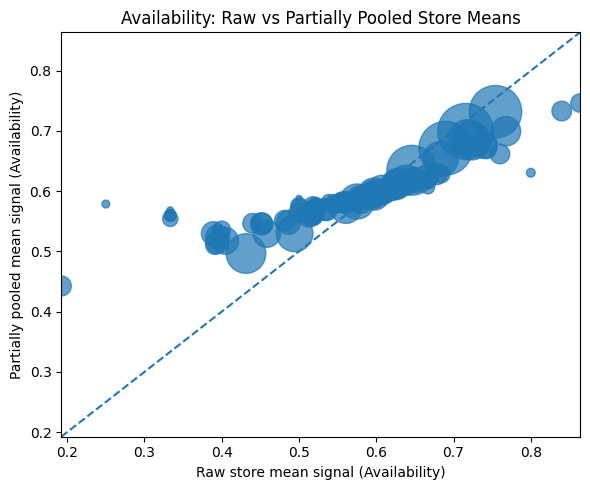

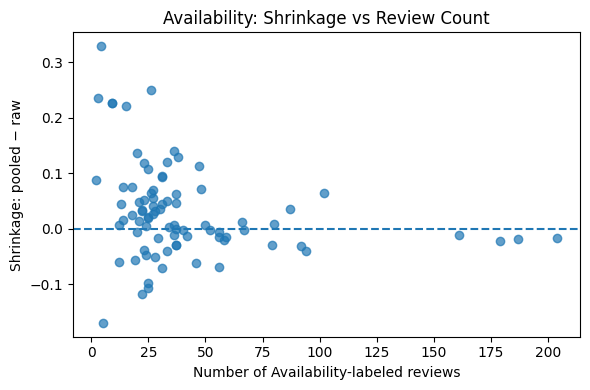


Diagnostic plots: Accessibility


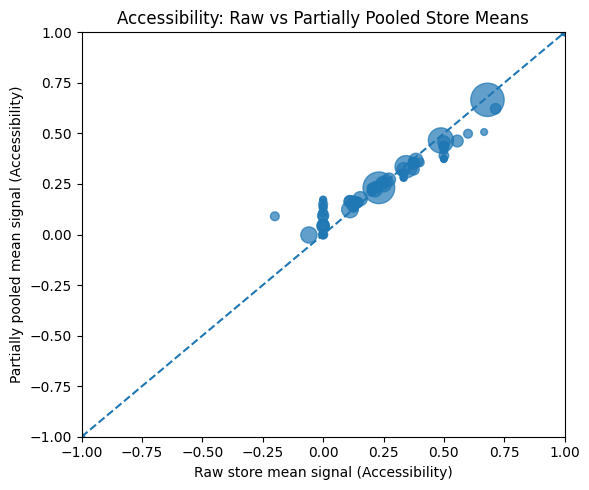

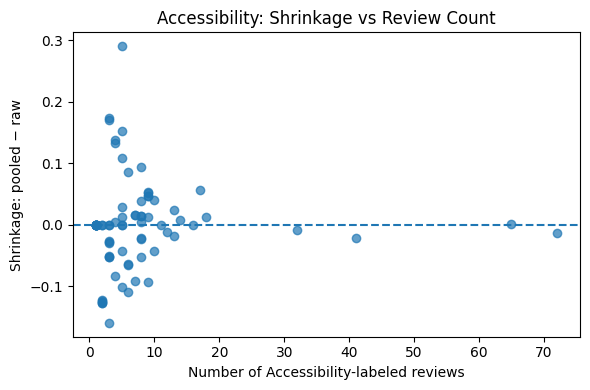


Diagnostic plots: Accommodation


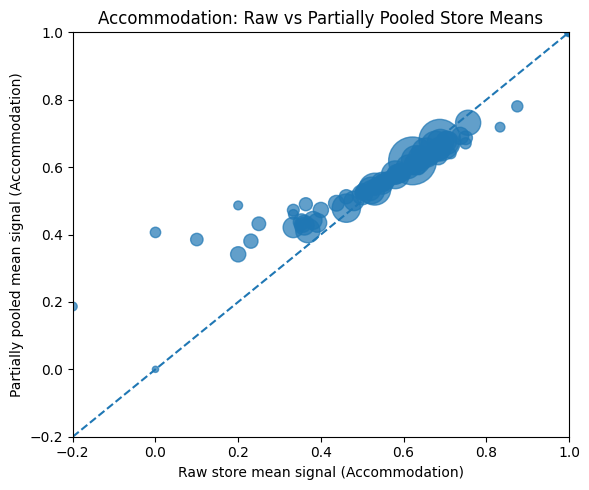

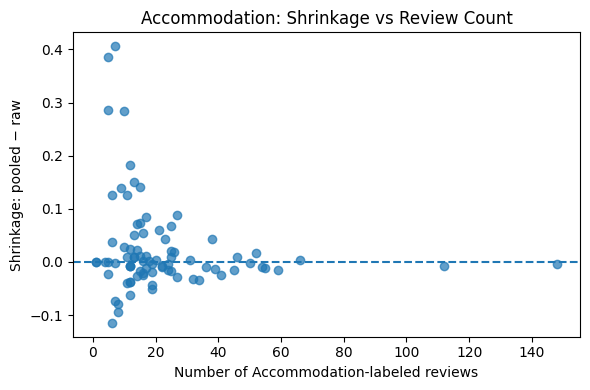


Diagnostic plots: Affordability


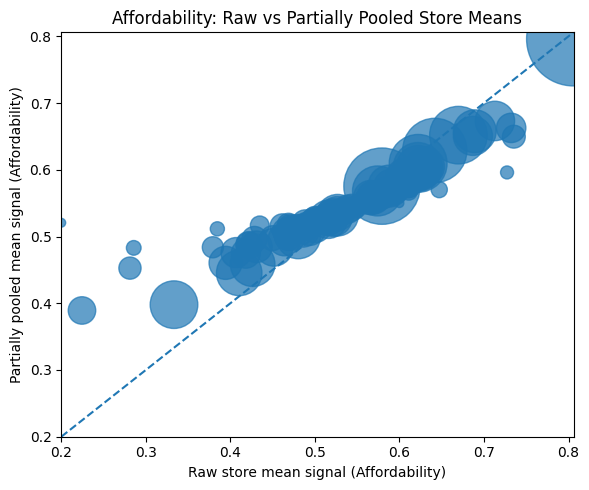

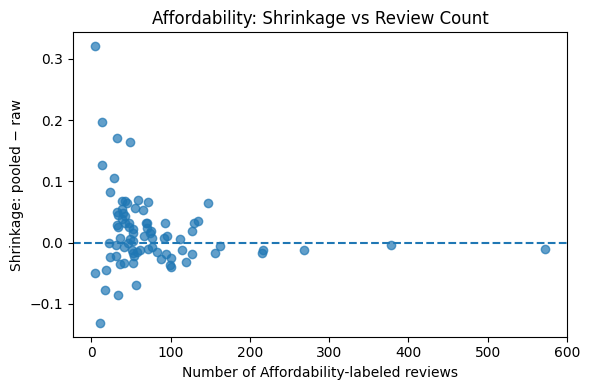


Diagnostic plots: Acceptability


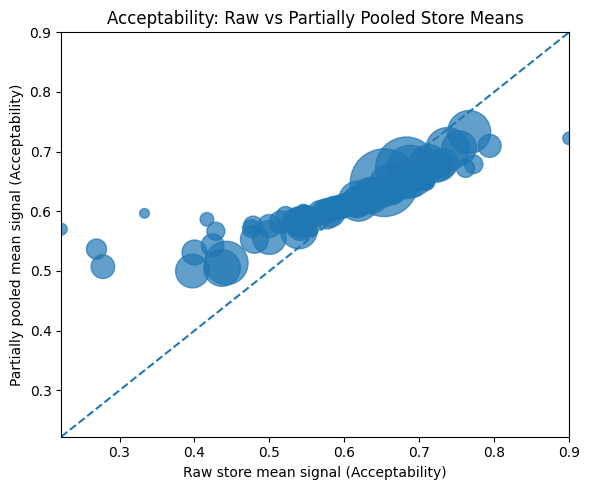

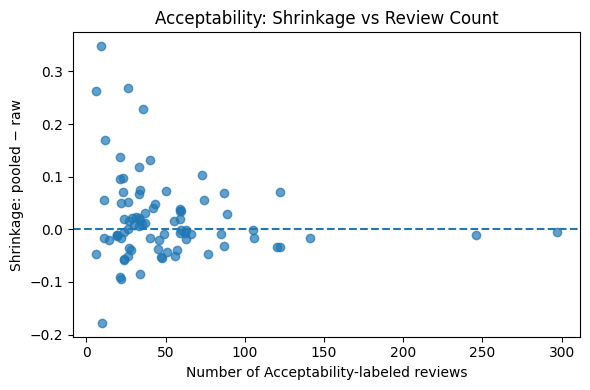

In [42]:
# ============================================================
# Plot partial pooling diagnostics for all dimensions
# ============================================================

for dim in DIM_ORDER:
    print("\n" + "=" * 60)
    print(f"Diagnostic plots: {dim}")
    print("=" * 60)

    plot_raw_vs_pooled(
        stores=stores,
        dim=dim,
    )

    plot_shrinkage_vs_review_count(
        stores=stores,
        dim=dim,
    )